# SportsMOT Basketball EDA

Exploratory analysis of the basketball split of SportsMOT: clip/annotation summary stats, track length, bounding box size, and occlusion distributions, plus a sample of annotated frames.

**Scope note:** only `train`/`val` basketball clips have ground truth â€” `test` labels are withheld by SportsMOT for the competition, so this notebook (and any training data built from it) is limited to those 30 clips.

## 0. Setup

In [56]:
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "src"))

from data_loading import BASKETBALL_SPLITS, DATASET_ROOT, build_dataset
from iou import max_offdiag_iou

OUTPUTS = Path.cwd().parent / "outputs"
OUTPUTS.mkdir(exist_ok=True)

## 1. Load data

Builds `clips_df` (one row per clip) and `annotations_df` (one row per bounding box) from the raw MOT-format files, caching both to `outputs/` so re-running the notebook doesn't re-parse ~228k annotation rows every time. Set `FORCE_REBUILD = True` after changing `src/data_loading.py`.

In [57]:
CLIPS_CACHE = OUTPUTS / "clips.csv"
ANNOTATIONS_CACHE = OUTPUTS / "annotations.csv"
FORCE_REBUILD = False

if CLIPS_CACHE.exists() and ANNOTATIONS_CACHE.exists() and not FORCE_REBUILD:
    clips_df = pd.read_csv(CLIPS_CACHE)
    annotations_df = pd.read_csv(ANNOTATIONS_CACHE)
else:
    clips_df, annotations_df = build_dataset(BASKETBALL_SPLITS)
    clips_df.to_csv(CLIPS_CACHE, index=False)
    annotations_df.to_csv(ANNOTATIONS_CACHE, index=False)

assert len(clips_df) == 30, (
    f"expected 30 basketball clips with gt (15 train + 15 val), got {len(clips_df)}"
)
print("clips_df:", clips_df.shape, " annotations_df:", annotations_df.shape)
clips_df.head()

clips_df: (30, 6)  annotations_df: (227673, 11)


,split,clip,framerate,seqlength,imwidth,imheight
0,train,v_-6Os86HzwCs_c001,25,825,1280,720
1,train,v_-6Os86HzwCs_c003,25,403,1280,720
2,train,v_-6Os86HzwCs_c007,25,550,1280,720
3,train,v_-6Os86HzwCs_c009,25,500,1280,720
4,train,v_2j7kLB-vEEk_c001,25,826,1280,720


## 2. Summary stats table

In [58]:
print("Clips per split:")
print(clips_df["split"].value_counts())

print("\nTotal frames (sum of seqlength):", clips_df["seqlength"].sum())
print("Total bounding boxes:", len(annotations_df))

print("\nFramerate distribution:")
print(clips_df["framerate"].value_counts())

print("\nResolution distribution:")
print(clips_df[["imwidth", "imheight"]].value_counts())

print("\nUnique annotation classes:", annotations_df["class"].unique())

Clips per split:
split
train    15
val      15
Name: count, dtype: int64

Total frames (sum of seqlength): 24941
Total bounding boxes: 227673

Framerate distribution:
framerate
25    30
Name: count, dtype: int64

Resolution distribution:
imwidth  imheight
1280     720         30
Name: count, dtype: int64

Unique annotation classes: [1]


## 3. Track length distribution

count     300.000000
mean      758.910000
std       265.463957
min       311.000000
25%       550.000000
50%       719.000000
75%       942.750000
max      1775.000000
Name: num_frames, dtype: float64

% tracks shorter than 10 frames: 0.0%


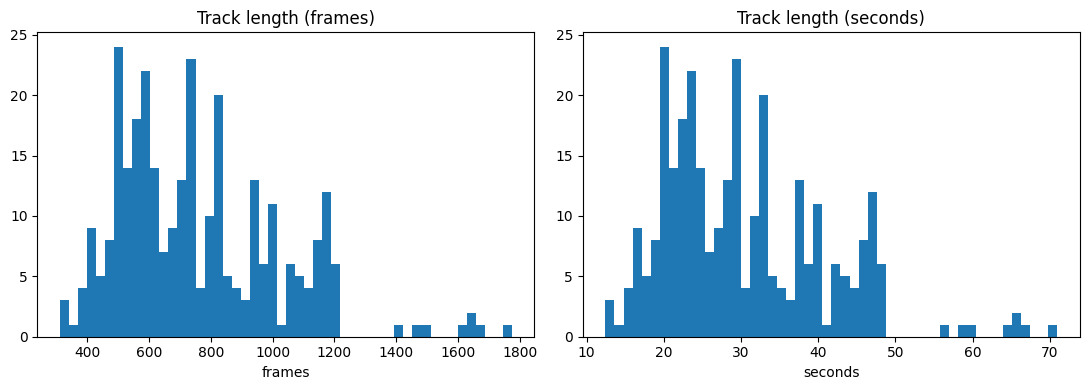

In [59]:
track_lengths = (
    annotations_df.groupby(["clip", "track_id"])["frame"]
    .count()
    .rename("num_frames")
    .reset_index()
)

framerate_by_clip = clips_df.set_index("clip")["framerate"]
track_lengths["seconds"] = (
    track_lengths["num_frames"] / track_lengths["clip"].map(framerate_by_clip)
)

print(track_lengths["num_frames"].describe())

short_track_frac = (track_lengths["num_frames"] < 10).mean()
print(f"\n% tracks shorter than 10 frames: {short_track_frac:.1%}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(track_lengths["num_frames"], bins=50)
axes[0].set_title("Track length (frames)")
axes[0].set_xlabel("frames")

axes[1].hist(track_lengths["seconds"], bins=50)
axes[1].set_title("Track length (seconds)")
axes[1].set_xlabel("seconds")
plt.tight_layout()
plt.show()

## 4. Bounding box size distribution

count    227673.000000
mean      14172.601692
std        7042.913934
min         480.000000
25%        9086.000000
50%       12600.000000
75%       17646.000000
max       72376.000000
Name: area, dtype: float64


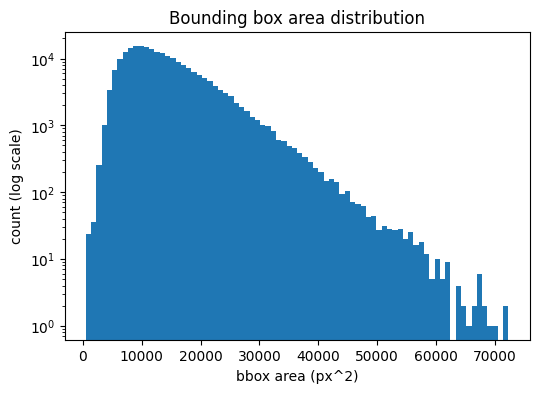

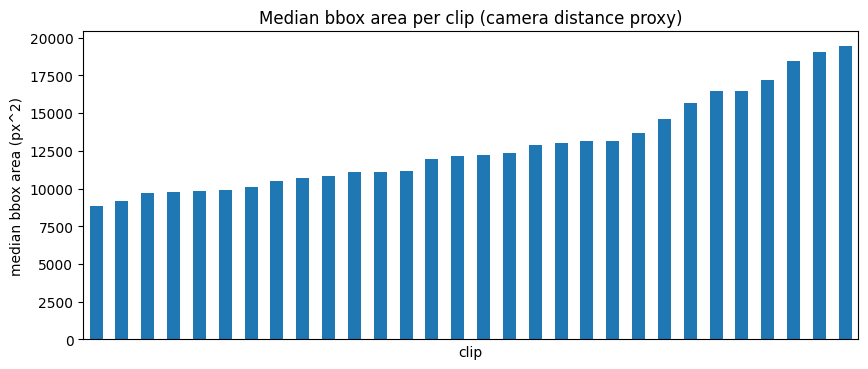

In [60]:
annotations_df["area"] = annotations_df["w"] * annotations_df["h"]

print(annotations_df["area"].describe())

plt.figure(figsize=(6, 4))
plt.hist(annotations_df["area"], bins=80, log=True)
plt.xlabel("bbox area (px^2)")
plt.ylabel("count (log scale)")
plt.title("Bounding box area distribution")
plt.show()

area_by_clip = annotations_df.groupby("clip")["area"].median().sort_values()
plt.figure(figsize=(10, 4))
area_by_clip.plot(kind="bar")
plt.ylabel("median bbox area (px^2)")
plt.title("Median bbox area per clip (camera distance proxy)")
plt.xticks([])
plt.show()

## 5. Occlusion frequency

For every `(clip, frame)`, compute the max pairwise IoU among player boxes present in that frame using `src/iou.py` (the same helper will get reused for tracker evaluation later, per the plan).

% frames with an occlusion event (IoU > 0.3): 67.7%


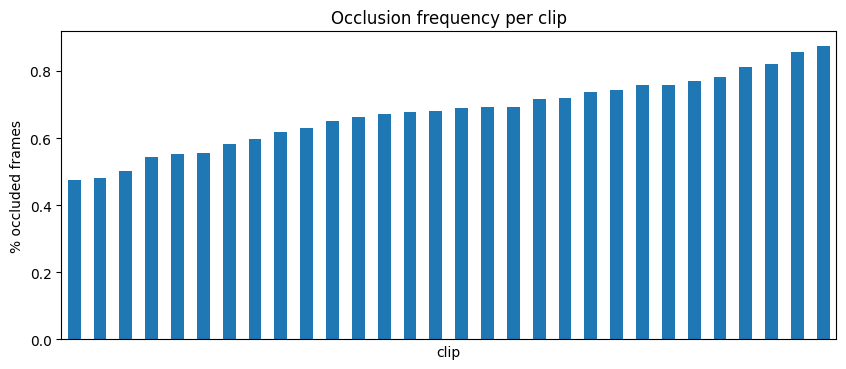

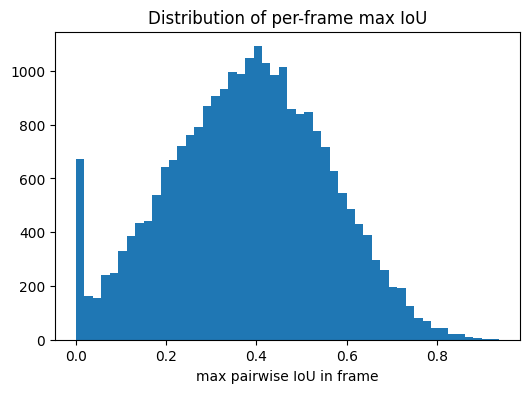

In [61]:
def frame_max_iou(group: pd.DataFrame) -> float:
    boxes = group[["x", "y", "w", "h"]].to_numpy(dtype=float)
    return max_offdiag_iou(boxes)

frame_groups = annotations_df.groupby(["clip", "frame"])
max_iou_per_frame = (
    frame_groups.apply(frame_max_iou, include_groups=False)
    .rename("max_iou")
    .reset_index()
)

OCCLUSION_THRESHOLD = 0.3
max_iou_per_frame["occluded"] = max_iou_per_frame["max_iou"] > OCCLUSION_THRESHOLD

overall_occluded_frac = max_iou_per_frame["occluded"].mean()
print(
    f"% frames with an occlusion event (IoU > {OCCLUSION_THRESHOLD}): "
    f"{overall_occluded_frac:.1%}"
)

occluded_by_clip = (
    max_iou_per_frame.groupby("clip")["occluded"].mean().sort_values()
)

plt.figure(figsize=(10, 4))
occluded_by_clip.plot(kind="bar")
plt.ylabel("% occluded frames")
plt.title("Occlusion frequency per clip")
plt.xticks([])
plt.show()

plt.figure(figsize=(6, 4))
plt.hist(max_iou_per_frame["max_iou"], bins=50)
plt.xlabel("max pairwise IoU in frame")
plt.title("Distribution of per-frame max IoU")
plt.show()

## 6. Sample annotated frames

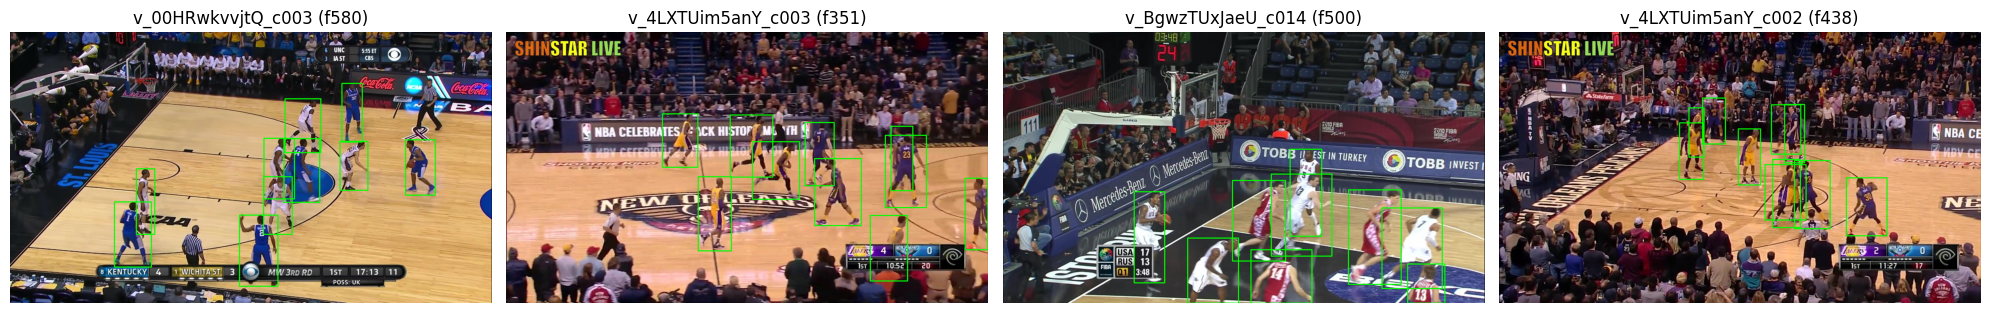

In [62]:
def clip_dir_for(split: str, clip: str) -> Path:
    return DATASET_ROOT / split / split / clip

def draw_gt_frame(split: str, clip: str, frame: int) -> np.ndarray:
    clip_path = clip_dir_for(split, clip)
    img_path = clip_path / "img1" / f"{frame:06d}.jpg"
    img = cv2.imread(str(img_path))
    boxes = annotations_df[
        (annotations_df["clip"] == clip) & (annotations_df["frame"] == frame)
    ]
    for row in boxes.itertuples():
        x, y, w, h = int(row.x), int(row.y), int(row.w), int(row.h)
        cv2.rectangle(img, (x, y), (x + w, y + h), (0, 255, 0), 2)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

sample_clips = clips_df.sample(4)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, row in zip(axes, sample_clips.itertuples()):
    frame_num = row.seqlength // 2  # a frame from the middle of the clip
    img = draw_gt_frame(row.split, row.clip, frame_num)
    ax.imshow(img)
    ax.set_title(f"{row.clip} (f{frame_num})")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 8. Players per frame distribution

count    24941.000000
mean         9.128463
std          1.446013
min          3.000000
25%          9.000000
50%         10.000000
75%         10.000000
max         10.000000
Name: num_players, dtype: float64

Value counts:
num_players
3       202
4       220
5       403
6       810
7      1908
8      2522
9      2980
10    15896
Name: count, dtype: int64


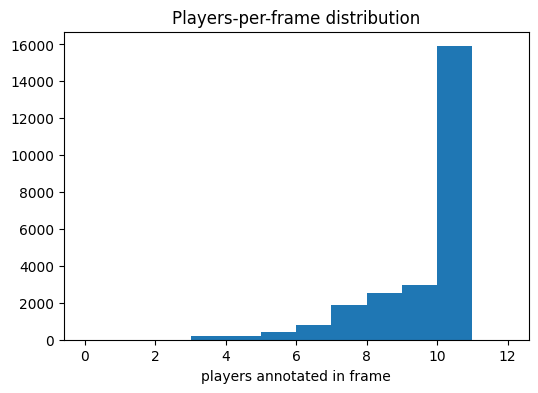

In [63]:
players_per_frame = (
    annotations_df.groupby(["clip", "frame"]).size()
    .rename("num_players")
    .reset_index()
)

print(players_per_frame["num_players"].describe())
print("\nValue counts:")
print(players_per_frame["num_players"].value_counts().sort_index())

plt.figure(figsize=(6, 4))
plt.hist(players_per_frame["num_players"], bins=range(0, 13))
plt.xlabel("players annotated in frame")
plt.title("Players-per-frame distribution")
plt.show()

## 9. Track continuity (gaps)

`visibility` in `gt.txt` is a constant placeholder (Section 2), so it can't tell us when a track is occluded. A more direct proxy: does a track's player ID ever disappear and reappear later in the same clip (non-contiguous frame numbers)? A gap usually means the player was occluded or left frame long enough that the tracker/annotator lost and never recovered the same ID mid-gap.

% tracks with at least one gap: 55.3%

Gap length (frames) among tracks that have one:
count    166.000000
mean      85.740964
std       51.932349
min        1.000000
25%       49.000000
50%       87.500000
75%      117.500000
max      261.000000
Name: max_gap, dtype: float64


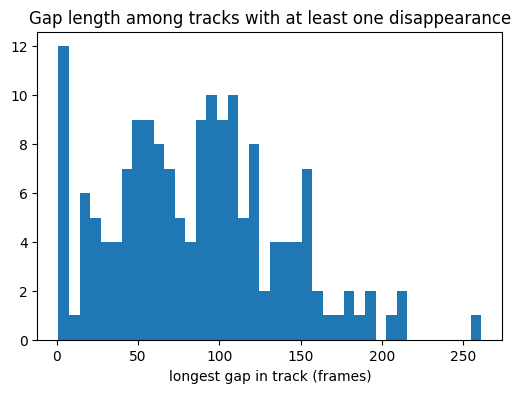

In [64]:
def track_span_and_gap(group: pd.DataFrame) -> pd.Series:
    frames = np.sort(group["frame"].to_numpy())
    diffs = np.diff(frames)
    max_gap = int(diffs.max() - 1) if len(diffs) else 0
    return pd.Series({
        "num_frames": len(frames),
        "span": int(frames[-1] - frames[0] + 1),
        "max_gap": max_gap,
    })

track_info = (
    annotations_df.groupby(["clip", "track_id"])
    .apply(track_span_and_gap, include_groups=False)
    .reset_index()
)
track_info["has_gap"] = track_info["max_gap"] > 0

print(f"% tracks with at least one gap: {track_info['has_gap'].mean():.1%}")
print("\nGap length (frames) among tracks that have one:")
print(track_info.loc[track_info["has_gap"], "max_gap"].describe())

plt.figure(figsize=(6, 4))
plt.hist(track_info.loc[track_info["has_gap"], "max_gap"], bins=40)
plt.xlabel("longest gap in track (frames)")
plt.title("Gap length among tracks with at least one disappearance")
plt.show()

## 10. Train vs. val comparison

Sanity-check that `train` and `val` aren't drawn from meaningfully different distributions before relying on val for model selection later.

Track length (frames) by split:
       count        mean         std    min    25%    50%     75%     max
split                                                                    
train  150.0  725.653333  284.812855  311.0  529.5  680.0  824.00  1775.0
val    150.0  792.166667  240.977105  384.0  589.5  783.0  987.25  1215.0

Bbox area by split:
          count          mean          std    min      25%      50%      75%  \
split                                                                          
train  108848.0  16012.362175  7521.715270  480.0  10439.0  14652.0  20124.0   
val    118825.0  12487.314513  6105.264493  544.0   8305.0  11097.0  15136.0   

           max  
split           
train  68599.0  
val    72376.0  

Occlusion fraction by split:
split
train    0.663033
val      0.689974
Name: occluded, dtype: float64


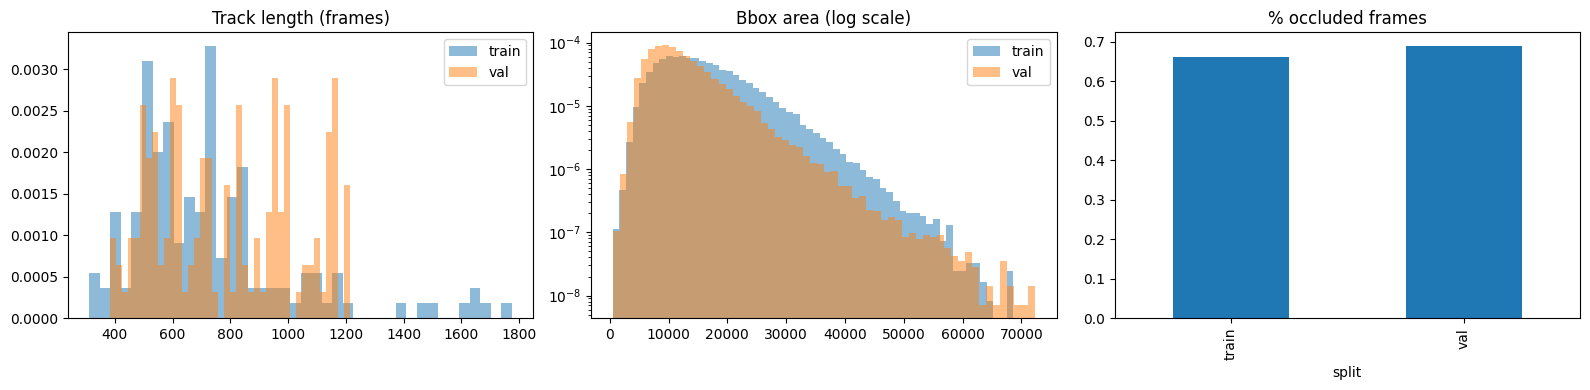

In [65]:
track_lengths_split = track_lengths.merge(clips_df[["clip", "split"]], on="clip")
occluded_split = max_iou_per_frame.merge(clips_df[["clip", "split"]], on="clip")

print("Track length (frames) by split:")
print(track_lengths_split.groupby("split")["num_frames"].describe())

print("\nBbox area by split:")
print(annotations_df.groupby("split")["area"].describe())

print("\nOcclusion fraction by split:")
print(occluded_split.groupby("split")["occluded"].mean())

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for split, sub in track_lengths_split.groupby("split"):
    axes[0].hist(sub["num_frames"], bins=40, alpha=0.5, label=split, density=True)
axes[0].set_title("Track length (frames)")
axes[0].legend()

for split, sub in annotations_df.groupby("split"):
    axes[1].hist(sub["area"], bins=60, alpha=0.5, label=split, density=True, log=True)
axes[1].set_title("Bbox area (log scale)")
axes[1].legend()

occluded_split.groupby("split")["occluded"].mean().plot(kind="bar", ax=axes[2])
axes[2].set_title("% occluded frames")

plt.tight_layout()
plt.show()

## 11. Artifacts / biases

- **macOS AppleDouble files (`._*.jpg`)** were present in the raw downloaded archives and inflated raw frame counts by ~2x under naive globbing. Filtered these out and verified counts against `seqinfo.ini`'s `seqLength`; confirmed 0 remain under `data/sportsmot`.
- **`test` split has no ground truth.** `splits_txt/basketball.txt` lists 80 clip names, but 50 of them are in `test`, which SportsMOT withholds labels for (no `gt/` folder at all â€” competition holdout). All EDA and any training data built from this must therefore come from the 30 clips (15 train + 15 val) that actually have annotations.
- **No ball annotations exist anywhere in SportsMOT.** `annotations_df["class"]` is `{1}` only (players) across every clip. Ball tracking will need a separate labeling source (synthetic labels, a small hand-labeled set, or a color/motion heuristic) â€” this dataset cannot supervise or evaluate it on its own.
- **Slightly different camera angles are used.** Most camera angles are on the sideline, but there are different vertical angles. The sideline angle would be the most consistent for player tracking and is also the most common in broadcasts, so training on different vertical angles would be helpful in limiting the impact of occlusion.
- **Occlusion scenarios:** Many inbound/after time out plays involve grouping players in the same area. Switching matchups mid-possession also creates occlusions, so this could be used to identify more types of plays